# Topic Modeling
Unsupervised topic discovery on YouTube crisis comments using BERTopic.

## Methodology

### Motivation
After scoring comments by sentiment, we apply topic modeling to uncover
*what* people are talking about — blame attribution, calls for justice,
grief, misinformation, political critique — giving qualitative structure
to the quantitative sentiment scores.

### Approach
We use **BERTopic** — an embedding-based topic model that:
1. Encodes each comment into a dense vector (sentence-transformers)
2. Reduces dimensionality (UMAP) for clustering stability
3. Clusters semantically similar comments (HDBSCAN)
4. Extracts descriptive terms per cluster (c-TF-IDF)

### Pipeline

| Phase | Step | Description |
|---|---|---|
| **1. Preprocessing** | Text cleaning | Lowercase, strip punctuation/URLs/digits, remove English + Filipino stopwords |
| **2. Embedding** | Sentence vectors | `paraphrase-multilingual-MiniLM-L12-v2` (12 languages, 384-d) |
| **3. Reduction** | UMAP | 384-d → 5-d for density-based clustering |
| **4. Clustering** | HDBSCAN | Soft clustering; non-assigned → noise cluster (-1) |
| **5. Representation** | c-TF-IDF | Top unigrams/bigrams per cluster as topic descriptors |
| **6. Labeling** | Manual annotation | Human-readable labels from top terms + sample comments |

### Cross-Analysis
Topic assignments are joined with sentiment labels, shouting flags,
and video IDs to answer:
- *Which topics dominate each news source?*
- *Do certain topics carry more negative sentiment?*
- *Are shouted comments concentrated in specific topics?*

### Input / Output
- **Input:** `scored_{BATCH_NAME}.csv` from sentiment analysis
- **Output:** Topic-labeled DataFrame + per-video topic profile + topic × sentiment cross-tab

In [1]:
import pandas as pd
import numpy as np
import ast
import os
os.environ["CUDA_VISIBLE_DEVICES"] = ""
import re
import string
import nltk

from nltk.corpus import stopwords
from bertopic import BERTopic
from sentence_transformers import SentenceTransformer

import spacy

# Patch transformers for spacy-transformers compatibility
import transformers.tokenization_utils
import transformers.tokenization_utils_base
transformers.tokenization_utils.BatchEncoding = transformers.tokenization_utils_base.BatchEncoding

from dotenv import load_dotenv
from google import genai
from google.genai import types

import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams["figure.dpi"] = 150

/home/mbchavezz/Coding/Research/crisis-management-analysis/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Configuration
Phase selector. Papermill injects `phase_name` per run.

In [ ]:
# --- papermill parameters (injected by runner) ---
crisis_name = "ateneo-drowning"  # default; overridden by papermill
phase_name = "04-reckoning"  # default; overridden by papermill

In [ ]:
# --- CONFIG ---
BASE_DIR = f"../output/{crisis_name}/youtube-comments/sentiment-analysis"
BATCH_NAME = f"scored_{phase_name}.csv"
BATCH_PATH = os.path.join(BASE_DIR, BATCH_NAME)

## Load Batch
Read the scored CSV. Each row is a cleaned comment with
`sentiment_label`, `sentiment_score`, `is_shouting`, and
`sentences`. These features feed into cross-analysis
after topic modeling.

In [3]:
batch_df = pd.read_csv(BATCH_PATH)
print(f"Loaded {len(batch_df)} comments from {BATCH_NAME}")

# Parse the sentences column from stringified list back to Python list
batch_df['sentences'] = batch_df['sentences'].apply(ast.literal_eval)

batch_df[["text", "sentiment_label", "sentiment_score", "is_shouting"]].head()


Loaded 752 comments from scored_03.1-baldwin_apology.csv


,text,sentiment_label,sentiment_score,is_shouting
0,an eye for an eye and tooth for tooth.stop thi...,NEGATIVE,0.713356,0
1,justice for the 2 young guys and no one will g...,NEGATIVE,0.443520,0
2,if he apologizes that means guilty in the deat...,NEGATIVE,0.873826,0
3,you should stay here in the philippines until ...,NEUTRAL,0.603017,0
4,did you go to their wake?,NEUTRAL,0.661816,0


## Stopwords

Three sources merged into one set:

| Source | Provides | Origin |
|---|---|---|
| **nltk** | ~179 English stopwords | `nltk.corpus.stopwords` |
| **calamanCy** | ~147 Tagalog stopwords | spaCy defaults from `tl_calamancy_md` |
| **Custom** | ~30 noise words | `po`, `opo`, `kasi`, `lang`, `yung`, `nung`, etc. |

Custom additions cover common comment filler that isn't in
standard stopword lists.


In [4]:
nltk.download("stopwords", quiet=True)

en_stop = set(stopwords.words("english"))
nlp_tl = spacy.load("tl_calamancy_md")
tl_stop = nlp_tl.Defaults.stop_words

custom_stop = {
    "po", "opo", "kasi", "eh", "ah", "oh", "talaga", "naman",
    "lang", "pa", "na", "din", "rin", "raw", "daw", "yung",
    "nung", "sya", "ung", "ng", "sa", "ako", "ikaw", "tayo",
    "niya", "natin", "sila", "amin", "atin",
}

STOPWORDS = en_stop | tl_stop | custom_stop
print(f"Stopwords: {len(STOPWORDS)} total")
print(f"  English:  {len(en_stop)}")
print(f"  Tagalog:  {len(tl_stop)}")
print(f"  Custom:   {len(custom_stop)}")
print(f"Sample TL: {sorted(tl_stop)[:10]}")


Stopwords: 359 total
  English:  198
  Tagalog:  147
  Custom:   29
Sample TL: ['akin', 'aking', 'ako', 'alin', 'am', 'amin', 'aming', 'ang', 'ano', 'anumang']


## Text Cleaning

Apply a lightweight cleaning pipeline for topic modeling:

- Lowercase
- Remove URLs
- Strip punctuation
- Remove digits
- Filter stopwords + tokens shorter than 3 characters

Cleaned text is stored in a new `text_clean` column.
The original `text` column is preserved.


In [5]:
def clean_for_topics(text: str) -> str:
    text = text.lower()
    text = re.sub(r"https?://\S+", "", text)
    text = text.translate(str.maketrans("", "", string.punctuation))
    text = re.sub(r"\d+", "", text)
    tokens = [w for w in text.split() if w not in STOPWORDS and len(w) > 2]
    return " ".join(tokens)

batch_df["text"] = batch_df["text"].fillna("")

batch_df["text_clean"] = batch_df["text"].apply(clean_for_topics)
corpus = batch_df["text_clean"].tolist()

print(f"Corpus: {len(corpus)} documents")
print(f"Avg tokens/doc before: {np.mean([len(t.split()) for t in batch_df['text']]):.0f}")
print(f"Avg tokens/doc after:  {np.mean([len(t.split()) for t in corpus]):.0f}")


Corpus: 752 documents
Avg tokens/doc before: 27
Avg tokens/doc after:  14


## Embeddings

Encode each cleaned comment into a dense vector using
`sentence-transformers` for semantic clustering.

### Model

`paraphrase-multilingual-MiniLM-L12-v2` — chosen because:
- **Multilingual**: supports English + Tagalog + code-switched text
- **384-dimensional**: compact enough for UMAP reduction
- **Sentence-level**: trained on NLI/STS pairs for semantic similarity
  (critical for BERTopic's clustering quality)


In [6]:
EMBEDDING_MODEL = "paraphrase-multilingual-MiniLM-L12-v2"
# CUDA when available, otherwise CPU; never auto-select Apple MPS (reproducibility)
import torch
embedding_model = SentenceTransformer(
    EMBEDDING_MODEL, device="cuda" if torch.cuda.is_available() else "cpu"
)

print(f"Encoding {len(corpus)} documents with {EMBEDDING_MODEL}...")
embeddings = embedding_model.encode(
    corpus,
    show_progress_bar=True,
    batch_size=64,
)
print(f"Embedding shape: {embeddings.shape}")


Encoding 752 documents with paraphrase-multilingual-MiniLM-L12-v2...


Batches: 100%|██████████| 12/12 [00:10<00:00,  1.13it/s]

Embedding shape: (752, 384)


## BERTopic Model

Fit the topic model on the precomputed embeddings.

### Pipeline

| Step | Component | What it does |
|---|---|---|
| **1. Reduce** | UMAP (n_neighbors=15, n_components=5) | 384-d → 5-d for clustering stability |
| **2. Cluster** | HDBSCAN (min_cluster_size=10) | Density-based; unassigned → noise (-1) |
| **3. Reduce to 10** | BERTopic merge | Merges smaller topics into nearest larger topic until 10 remain (excl. noise) |
| **4. Represent** | c-TF-IDF | Top terms per cluster as topic descriptors |

### Why HDBSCAN over K-means?

| K-means | HDBSCAN (chosen) |
|---|---|
| Must set `k` upfront | Automatic — finds dense regions |
| Forces every point into a cluster | Noise cluster for off-topic comments |
| Spherical clusters only | Any shape (density-connected) |

For crisis comments, we don’t know the number of themes ahead of time.
HDBSCAN naturally finds them and isolates noise (spam, single-word comments).

### How HDBSCAN Works

Hierarchical Density-Based Spatial Clustering of Applications with Noise.

1. **Build a mutual reachability graph** — each comment (5-d UMAP point)
   is connected to its nearest neighbors. Dense regions get tight connections,
   sparse regions get loose ones.

2. **Create a hierarchy** — edges are removed in order of decreasing distance,
   producing a dendrogram of clusters at every density threshold.

3. **Extract stable clusters** — the algorithm selects clusters that persist
   across a wide range of density thresholds. Fluctuating clusters are pruned;
   only robust groupings remain.

4. **Assign noise** — points that never form a stable cluster are labeled `-1`.

### Why This Matters for Crisis Comments

| Property | Effect |
|---|---|
| **No fixed `k`** | HDBSCAN finds natural clusters; `nr_topics=10` merges smaller topics into the 10 most coherent |
| **Noise handling** | Spam, single words, or off-topic comments → `-1` instead of polluting a real topic |
| **Variable density** | Some themes are tight (e.g., “RIP” comments), others diffuse (e.g., “political critique”) — HDBSCAN handles both |
| **Outlier tolerance** | A heated comment with unusual vocabulary doesn’t force a new cluster or distort an existing one |

In [7]:
topic_model = BERTopic(
    embedding_model=embedding_model,
    min_topic_size=10,
    nr_topics=10,
    verbose=True,
)

topics, probs = topic_model.fit_transform(corpus, embeddings)

n_topics = len(set(topics)) - (1 if -1 in topics else 0)
n_noise = sum(1 for t in topics if t == -1)
print(f"\nTopics found: {n_topics}")
print(f"Noise cluster (-1): {n_noise} comments ({n_noise / len(topics):.1%})")


2026-06-25 14:25:15,876 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-06-25 14:25:27,253 - BERTopic - Dimensionality - Completed ✓
2026-06-25 14:25:27,254 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-06-25 14:25:27,310 - BERTopic - Cluster - Completed ✓
2026-06-25 14:25:27,311 - BERTopic - Representation - Extracting topics using c-TF-IDF for topic reduction.
2026-06-25 14:25:27,372 - BERTopic - Representation - Completed ✓
2026-06-25 14:25:27,373 - BERTopic - Topic reduction - Reducing number of topics
2026-06-25 14:25:27,389 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-06-25 14:25:27,429 - BERTopic - Representation - Completed ✓
2026-06-25 14:25:27,431 - BERTopic - Topic reduction - Reduced number of topics from 13 to 10



Topics found: 9
Noise cluster (-1): 199 comments (26.5%)


In [8]:
topic_model.get_topic_info().head(15)

,Topic,Count,Name,Representation,Representative_Docs
0,-1,199,-1_ateneo_families_two_coach,"[ateneo, families, two, coach, sorry, family, ...",[part life people born people live people die—...
1,0,183,0_yan_mangyari_wala_buhay,"[yan, mangyari, wala, buhay, sorry, anak, nman...",[jasonclement pang muntikan ngang malunod dati...
2,1,158,1_coach_training_players_basketball,"[coach, training, players, basketball, nya, te...",[geminisagekvdo alam kalagayan dagat time poss...
3,2,69,2_pool_water_swimming_training,"[pool, water, swimming, training, ocean, dange...",[⁠​⁠toddcrumpler horrible accident could preve...
4,3,37,3_bald_cryingface_bruhh_facewithtearsofjoyface...,"[bald, cryingface, bruhh, facewithtearsofjoyfa...",[mostly bald man masasamang damo like killer c...
5,4,28,4_negligence_accident_happen_blaming,"[negligence, accident, happen, blaming, act, d...",[sorry isnt enough wont bring back lives atene...
6,5,25,5_justice_god_find_rene,"[justice, god, find, rene, pray, two, perhaps,...",[university held accountable revisit system lo...
7,6,21,6_apology_apologize_face_video,"[apology, apologize, face, video, apologies, l...",[take responsibility failure repent make resti...
8,7,19,7_resign_blood_hands_baldwin,"[resign, blood, hands, baldwin, tab, uaap, res...",[resign tab baldwin coaching staff drama blood...
9,8,13,8_jail_man_sorry_want,"[jail, man, sorry, want, enough, say, time, co...","[send man jail, happen say sorry kind training..."


In [9]:
topic_model.visualize_barchart(top_n_topics=10, n_words=10)

In [10]:
topic_model.visualize_distribution(probs, min_probability=0.05)

## Topic Labeling

Each topic cluster is labeled by an LLM via the Gemini API.
Final labels for all phases come from `gemma-4-26b-a4b-it`
(`02-analysis/youtube/relabel_topics_gemma.py`, temperature 0).
Earlier passes used `gemini-2.5-flash` and `gemini-3.5-flash-lite`
(see `MODEL` history in the labeling cell); all were overwritten
by the Gemma pass.
Top 10 c-TF-IDF terms + 5 sample comments are sent per topic.
Labels are reviewed and manually overridden as needed.


In [ ]:
import time

load_dotenv("../../.env")
client = genai.Client(api_key=os.environ["GEMINI_API_KEY"])

# MODEL = "gemma-4-31b-it"
# MODEL = "gemini-2.5-flash"  # retired for new keys
# MODEL = "gemini-3.8-flash"  # overloaded 2026-10-13, retry later
# MODEL = "gemini-2.5-flash-lite"  # retired for new keys, use 3.5-flash-lite
MODEL = "gemini-3.5-flash-lite"

LLM_LABELS = {}
for topic_id in sorted([t for t in set(topics) if t != -1]):
    terms = topic_model.get_topic(topic_id)
    term_str = ", ".join([t[0] for t in terms[:10]])

    mask = [t == topic_id for t in topics]
    samples = batch_df.loc[mask, "text"].sample(min(5, sum(mask))).tolist()

    prompt = (
        "You are a crisis discourse analyst. Given the top terms "
        "and sample comments for a topic cluster, assign a short "
        "label (2-4 words).\n\n"
        f"Top terms: {term_str}\n"
        "Sample comments:\n"
        + "\n".join(f"- {s[:200]}" for s in samples[:5])
        + "\n\nLabel (2-4 words):"
    )

    for attempt in (1, 2, 3, 4, 5):
        try:
            response = client.models.generate_content(
                model=MODEL,
                contents=prompt,
                config=types.GenerateContentConfig(temperature=0),
            )
            break
        except Exception as e:
            msg = str(e)
            transient = any(c in msg for c in ("429", "503", "500", "overloaded", "overload"))
            if transient and attempt < 5:
                wait = 60 * 2 ** (attempt - 1)
                print(f"Transient API error, sleeping {wait}s (attempt {attempt}/5)...")
                time.sleep(wait)
            else:
                raise
    label = response.text.strip().strip("*").strip()
    LLM_LABELS[topic_id] = label
    print(f"Topic {topic_id}: {label}")
    time.sleep(13)  # free tier: 5 RPM -> 1 call per 12s


Topic 0: Accountability and Classism
Topic 1: Coach Accountability
Topic 2: Open Water Training Risks
Topic 3: Demand for Accountability
Topic 4: Accusations of Negligence
Topic 5: Demand for Justice
Topic 6: Apology and Accountability
Topic 7: Demands for Resignation
Topic 8: Calls for Incarceration


In [14]:
# Manual label overrides — fix typos or rename topics
# Uncomment and edit lines below, then re-run from here:
LABEL_OVERRIDES = {
    # 3: "Coach Accountability",
    # 5: "Demand for Justice (corrected)",
}

LLM_LABELS.update(LABEL_OVERRIDES)
FINAL_LABELS = LLM_LABELS.copy()

for tid, label in sorted(FINAL_LABELS.items()):
    print(f"  Topic {tid}: {label}")


  Topic 0: Accountability and Classism
  Topic 1: Coach Accountability
  Topic 2: Open Water Training Risks
  Topic 3: Demand for Accountability
  Topic 4: Accusations of Negligence
  Topic 5: Demand for Justice
  Topic 6: Apology and Accountability
  Topic 7: Demands for Resignation
  Topic 8: Calls for Incarceration


In [15]:
batch_df["topic_id"] = topics
batch_df["topic_label"] = batch_df["topic_id"].map(FINAL_LABELS)
batch_df[["text_clean", "topic_id", "topic_label"]].head(10)


,text_clean,topic_id,topic_label
0,eye eye tooth toothstop scripted lies hell,3,Demand for Accountability
1,justice young guys one thru,5,Demand for Justice
2,apologizes means guilty death players,-1,NaN
3,stay philippines justice given rene divine ber...,-1,NaN
4,wake,0,Accountability and Classism
5,coach tab nag papatunay basta kalbo masamang tao,1,Coach Accountability
6,surrender admit mistake jail best way apologize,6,Apology and Accountability
7,facewithopenmouthenragedfacesmilingfacewithhor...,3,Demand for Accountability
8,killer coach ataneoogreogreogreogreogreogre,1,Coach Accountability
9,mostly bald man masasamang damo like killer co...,3,Demand for Accountability


In [ ]:
# Extract top c-TF-IDF terms per topic for the validation review sheet
def get_top_terms(topic_id, n=10):
    if topic_id == -1:
        return ""
    terms = topic_model.get_topic(topic_id)
    if terms:
        return ", ".join([t[0] for t in terms[:n]])
    return ""

batch_df["top_terms"] = batch_df["topic_id"].apply(get_top_terms)
print(f"Top terms extracted for {batch_df['topic_id'].nunique() - (1 if -1 in batch_df['topic_id'].values else 0)} topics")
batch_df[["topic_id", "topic_label", "top_terms"]].drop_duplicates("topic_id").head(10)

## Cross-Analysis

Topic labels are joined with sentiment, shouting, and video metadata
to answer the research questions from the methodology:

- *Which topics dominate each news source (video_id)?*
  → Per-video topic distribution (crosstab + stacked bar)

- *Do certain topics carry more negative sentiment?*
  → Topic × sentiment_label heatmap

- *Are shouted comments concentrated in specific topics?*
  → Shouting ratio per topic


In [16]:
topic_x_video = pd.crosstab(
    batch_df["topic_label"],
    batch_df["video_id"],
    margins=True,
    margins_name="Total",
)
topic_x_video


video_id,NdV0_RCyEbA,OXk-mjXkQYs,Q6dGkiMTes0,dtvrM51u4Ks,ifzyUElx76Y,Total
topic_label,,,,,,
Accountability and Classism,0,5,161,14,3,183
Accusations of Negligence,0,1,27,0,0,28
Apology and Accountability,0,1,18,2,0,21
Calls for Incarceration,0,0,13,0,0,13
Coach Accountability,1,3,135,13,6,158
Demand for Accountability,0,1,33,3,0,37
Demand for Justice,0,1,21,3,0,25
Demands for Resignation,0,0,17,2,0,19
Open Water Training Risks,0,0,65,4,0,69


In [17]:
topic_x_sentiment = pd.crosstab(
    batch_df["topic_label"],
    batch_df["sentiment_label"],
    margins=True,
    margins_name="Total",
)
topic_x_sentiment


sentiment_label,NEGATIVE,NEUTRAL,POSITIVE,Total
topic_label,,,,
Accountability and Classism,118,52,13,183
Accusations of Negligence,28,0,0,28
Apology and Accountability,18,3,0,21
Calls for Incarceration,12,1,0,13
Coach Accountability,128,22,8,158
Demand for Accountability,28,8,1,37
Demand for Justice,12,4,9,25
Demands for Resignation,18,1,0,19
Open Water Training Risks,61,8,0,69


In [18]:
shouting_by_topic = batch_df.groupby("topic_label")["is_shouting"].agg(
    total="count",
    shouted="sum",
)
shouting_by_topic["shouting_ratio"] = shouting_by_topic["shouted"] / shouting_by_topic["total"]
shouting_by_topic.sort_values("shouting_ratio", ascending=False)


,total,shouted,shouting_ratio
topic_label,,,
Demands for Resignation,19,1,0.052632
Apology and Accountability,21,1,0.047619
Accountability and Classism,183,8,0.043716
Coach Accountability,158,6,0.037975
Accusations of Negligence,28,1,0.035714
Demand for Accountability,37,1,0.027027
Calls for Incarceration,13,0,0.000000
Demand for Justice,25,0,0.000000
Open Water Training Risks,69,0,0.000000


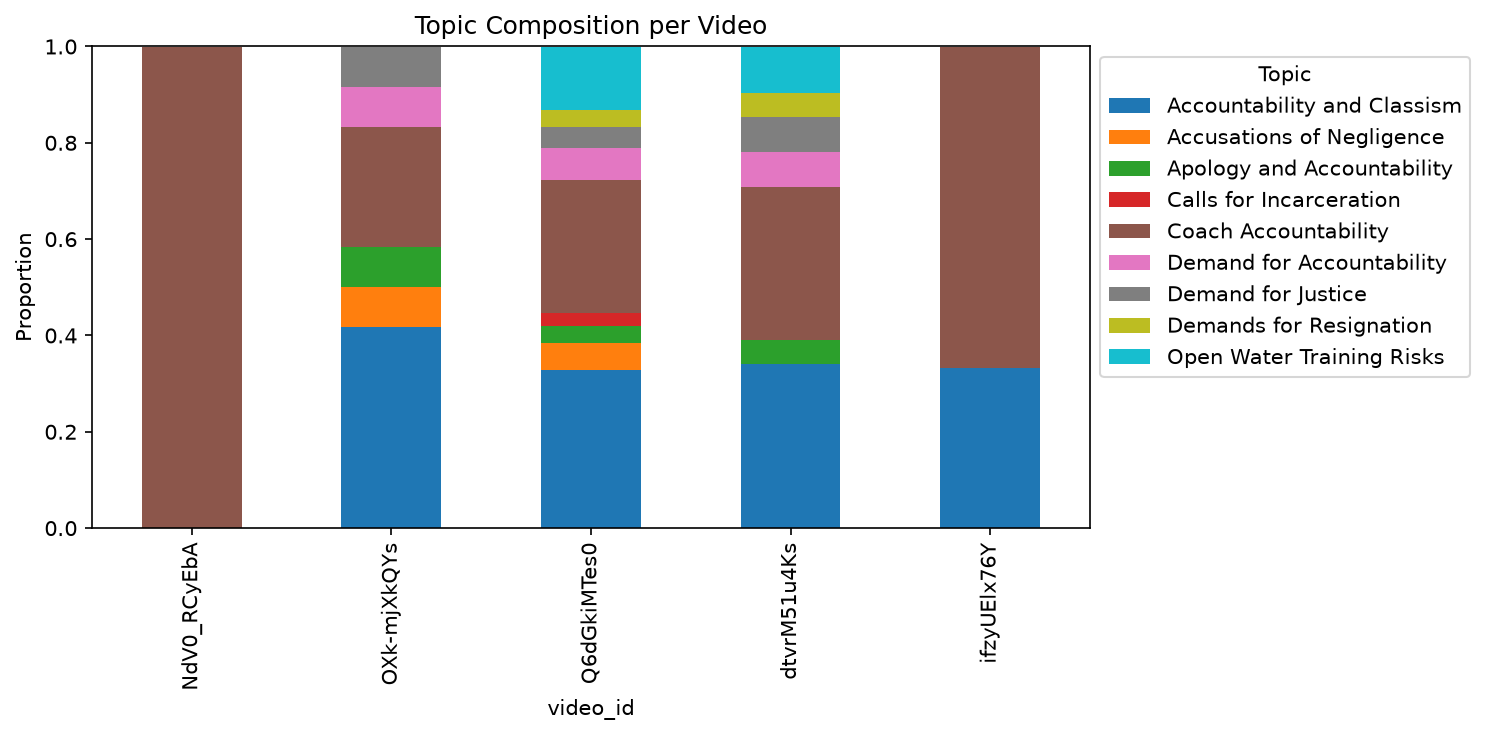

In [19]:
topic_video_pct = (
    batch_df.groupby(["video_id", "topic_label"])
    .size()
    .unstack(fill_value=0)
)
topic_video_pct = topic_video_pct.div(topic_video_pct.sum(axis=1), axis=0)

ax = topic_video_pct.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5),
    colormap="tab10",
)
plt.ylabel("Proportion")
plt.title("Topic Composition per Video")
plt.legend(title="Topic", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()


## Export

Save the topic-labeled comments for downstream use or
comparison across batches.

Columns preserved: text, video_id, sentiment_label, sentiment_score,
is_shouting, topic_id, topic_label, sentences.


In [20]:
output_dir = f"../output/{crisis_name}/youtube-comments/topic-modeling"
os.makedirs(output_dir, exist_ok=True)
output_path = os.path.join(output_dir, f"topics_{BATCH_NAME.replace('scored_', '')}")
batch_df.to_csv(output_path, index=False)
print(f"Exported {len(batch_df)} topic-labeled comments to {output_path}")


Exported 752 topic-labeled comments to ../output/topics_03.1-baldwin_apology.csv


In [21]:
# Post-hoc topic rename — edit labels in the exported CSV
# Run this cell after export to fix typos without re-running the pipeline.
df = pd.read_csv(output_path)

current = df[["topic_id", "topic_label"]].drop_duplicates().sort_values("topic_id")
display(current)

LABEL_RENAMES = {
    # 0: "Drowning Accountability (corrected)",
}

for tid, label in LABEL_RENAMES.items():
    df.loc[df["topic_id"] == tid, "topic_label"] = label

df.to_csv(output_path, index=False)
print("Labels updated in CSV.")


,topic_id,topic_label
2,-1,NaN
4,0,Accountability and Classism
5,1,Coach Accountability
13,2,Open Water Training Risks
0,3,Demand for Accountability
54,4,Accusations of Negligence
1,5,Demand for Justice
6,6,Apology and Accountability
15,7,Demands for Resignation
82,8,Calls for Incarceration


Labels updated in CSV.
